# Assignment #1: 
Measurements are not just readout!

In [ ]:
import pennylane as qp
import pennylane.numpy as np

# Teleportation

Quantum states can’t be copied (due to no-cloning) and are fragile to send directly, so teleportation is how you move qubits!

How it works? 

Alice and Bob share an entangled Bell pair; Alice does a Bell measurement on her half together with the qubit she wants to send and transmits the two resulting classical bits to Bob, who applies the matching X and/or Z correction to his half and so receives the state.

Implement the following circuit to run Teleportation!

Hints:
1)  Use `qp.StatePrep` for the input state
2) To run conditional measurements: measure the qubit ` m = qp.measure(..)` and then apply the conditional gate as `qp.cond(m, gate)`

![Teleportation](figures/teleport.png)

In [ ]:
dev = qp.device("default.qubit", wires=["S", "A", "B"])


   
@qp.qnode(dev)
def teleport(state):
    ### TODO ###
    
    # Input state

    # Bell state

    # Change Basis

    #Conditional Measurements
    
    return qp.density_matrix(wires=["B"]) 

state = np.array([1 / np.sqrt(2) + 0.3j, 0.4 - 0.5j])
_ = qp.draw_mpl(teleport, style="pennylane", level="device")(state)

The following cell will print "State successfully teleported!" if the circuit above is correct.

In [ ]:
def teleport_state(state):
    teleported_density_matrix = teleport(state)
    original_density_matrix = qp.math.dm_from_state_vector(state)

    if not np.allclose(teleported_density_matrix, original_density_matrix):
        raise ValueError(
            f"Alice's state ({state}) not teleported properly. "
            f"Final density matrix of Bob's subsystem: {teleported_density_matrix}"
        )
    print("State successfully teleported!")


teleport_state(state)

## How to implement CNOTs on devices with limited connectivity?

**Setup.** Qubits sit on a line $0, 1, \dots, n-1$ and two-qubit gates act only on neighbours.
We want $\mathrm{CNOT}_{c \to t}$ with control $c = 0$ and target $t = n-1$.

There's a simple way to do it, it basically just requires a CNOT gate and SWAP gates

In [ ]:
k = 2                 
n = 2 * k + 2               
c, t = 0, n - 1


def swap_cnot():
    """
    Returns:
        None. Only add the gates: this function is used as a subroutine
        inside a QNode.
    """
    ### TODO ###

## Dynamic Circuits w/ measurements

Now we'll explore how the same operation can be implemented in another way.
The qubits in between are ancillas in $|0\rangle$, grouped into $k = \tfrac{t-c-1}{2}$ Bell pairs.

Bell pair:

$$
|\Phi^+\rangle = \mathrm{CNOT}_{a \to b}\,(H \otimes I)\,|00\rangle
= \tfrac{1}{\sqrt{2}}\big(|00\rangle + |11\rangle\big),
$$

**Goal.** You will build a circuit whose depth does not depend on $n$, using
mid-circuit measurements (`qml.measure`) and classically controlled corrections (`qml.cond`).



Below you can see an example of the circuit for $k=1$ and in the next code cell you will have the instructions to follow to implement the circuit

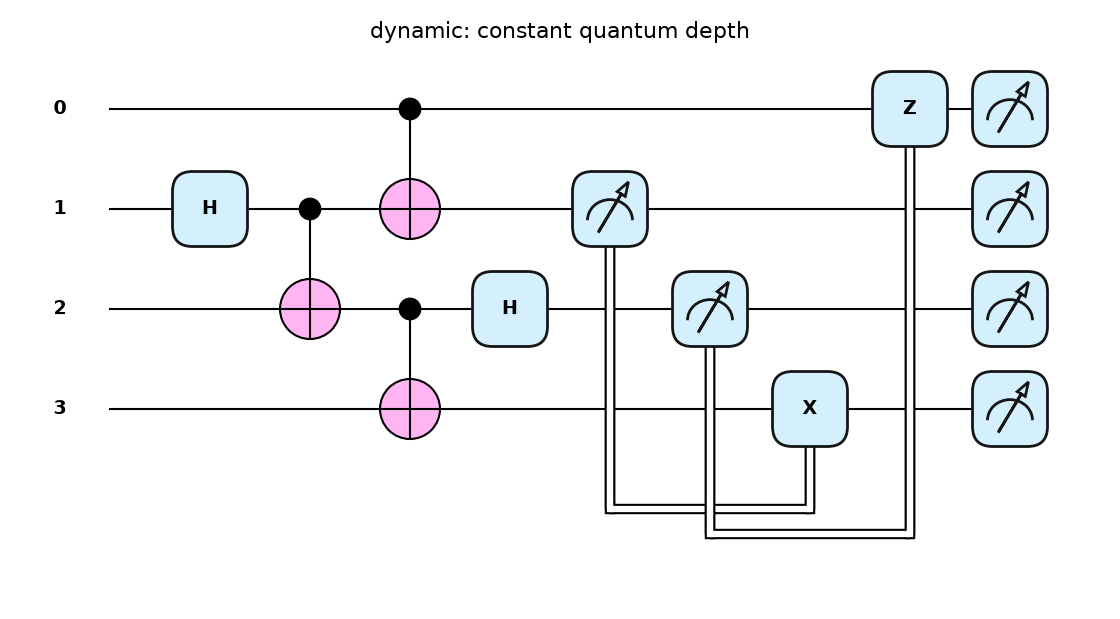

In [ ]:
def long_range_cnot():
    """
    Wires: c is the control (wire 0), t = 2k + 1 is the target,
    and wires 1, ..., 2k are ancillas initialized in |0>.

    Steps:
      1. Create a Bell pair on each ancilla pair (1, 2), (3, 4), ..., (2k-1, 2k).
      2. Connect the ends: a CNOT from the control c to the first ancilla,
         and a CNOT from the last ancilla to the target t.
      3. Join neighbouring Bell pairs: apply a CNOT on (2, 3), (4, 5), ...,
         (2k-2, 2k-1).
      4. Apply a Hadamard on every even ancilla (2, 4, ..., 2k).
      5. Measure all ancillas with qp.measure: the odd ones (1, 3, ...) give
         the Z outcomes, the even ones (2, 4, ...) give the X outcomes.
      6. Correct with qp.cond: if the parity of the Z outcomes is odd,
         apply X to t; if the parity of the X outcomes is odd, apply Z to c.

    Returns:
        None. Only add the gates: this function is used as a subroutine
        inside a QNode.
    """
    ### TODO ###


The code below will verify that both implementations match the ideal CNOT. Look at the resources required, what can u say about resources scaling when n increases?

In [ ]:
dev = qp.device("default.qubit")

def prep(p):
    qp.Rot(*p[:3], wires=c); qp.Rot(*p[3:], wires=t)
    

@qp.qnode(dev)
def dynamic(p):
    prep(p); long_range_cnot(); return qp.density_matrix([c, t])

@qp.qnode(dev)
def ideal(p):
    prep(p); qp.CNOT([c, t]); return qp.density_matrix([c, t])

p = np.random.uniform(0, 2 * np.pi, 6)
print("matches ideal CNOT:", np.allclose(dynamic(p), ideal(p)))


for name, circ in [("swap", swap_cnot),("dynamic", long_range_cnot),]:
    def wrapped(circ=circ):
        circ()
        return qp.state()
    res = qp.specs(qp.QNode(wrapped, dev))()
    r = res["resources"]
    print(f"{name}: total gates {r.num_gates}, depth {r.depth}, gates {dict(r.gate_types)}")
    fig, _ = qp.draw_mpl(qp.qnode(dev)(lambda: (circ(), qp.state())[1]),
                          decimals=None, style="pennylane")()
    fig.suptitle(f"{name}: depth grows with distance" if name == "swap"
                 else f"{name}: constant quantum depth", fontsize=16)

# Let's make some Noise..

What happens with real devices?
1) Add depolarizing noise to all the wires with prob .01
2) Do a coupling map where connectivity is nearest-neighbours, namely a linear chain.
3) Compiling Pipeline: do a simple pipeline with 2 rules: one to enforce the coupling map and a native gate set mapping to `"CNOT","Rot"`.


Guiding Questions:
1) Explore what happens by varying the error and scaling the distance, namely the number of qubits.
Be aware that noisy simulations require more time increasing the amount of qubits, hence there's no need to consider too big circuits.
2) Change topology: when is the dynamic trick not worth using at all?
3) Wait time during measurement. On real hardware, the control and target sit idle while the ancillas are measured and the results are processed. Add the new source of errors in `long_range_cnot()` right after the midcircuit-measurements:  `for w in (c, t): qp.DepolarizingChannel(p_wait, wires=w)`.  
How large can p_wait get before SWAP routing wins again? 
4) Readout errors: Measurements aren't perfect either. Flip each ancilla before it's measured and put the following before the measurements. Consider up to 1-3% error percentage. 


In [ ]:

k = 1              
n = 2 * k + 2                
c, t = 0, n - 1


coupling_map = ### TODO ###


# Noise Model : add depolarzing noise to all the wires
def depol(op):                                          
    ### TODO ###

noise = qp.NoiseModel({qp.noise.op_in(["CNOT", "SWAP", "CZ"]): depol})


# Compiling Pipeline: do a simple pipeline with 2 rules: one to enforce the coupling map and a native gate set mapping to "CNOT" and "Rot".
pipeline = qp.CompilePipeline(
      ### TODO ###
)

# Select the device
dev = ### TODO ###

def make(body, route=False):
    @qp.qnode(dev)
    def circ(p):
        qp.Rot(*p[:3], wires=c); 
        qp.Rot(*p[3:], wires=t)
        body()
        return qp.density_matrix(range(n) if route else [c, t])   
    qn = pipeline(circ) if route else circ
    def f(p, noisy=False):
        rho = (qp.add_noise(qn, noise) if noisy else qn)(p)
        return qp.math.reduce_dm(rho, indices=[c, t]) if route else rho
    return f
 
ideal = make(lambda: qp.CNOT([c, t]))
p = np.random.uniform(0, 2*np.pi, 6)
for name, f in [("swap", make(lambda: qp.CNOT([c, t]), route=True)), ("dynamic", make(long_range_cnot))]:
    print(f"{name:8s} F_clean={qp.math.fidelity(f(p), ideal(p)):.3f}  "
          f"F_noisy={qp.math.fidelity(f(p, noisy=True), ideal(p)):.3f}")

Feel free to do extra-experiments!

In [ ]:
### TODO (if you want :) ) ###